In [1]:
"""This file contains the code that is to run the analysis"""
import warnings
import numpy as np
import matplotlib.pyplot as plt
import orbits
import dynamics
import linearize
import methods
import plots

warnings.filterwarnings("ignore", message="The iteration is not making good progress")   # fsolve, harmless as in Project 1

In [2]:
planets, orbiters = orbits.get_starting_bodies()

x0, mu, names = dynamics.build(planets, orbiters)
x0 = dynamics.bary_shift(x0, mu)

n_bodies = len(names)
n_massive = len(planets)


f = lambda x, t: dynamics.nbody_rhs(x, mu)

jacobian = linearize.jacobian(n_bodies)
J0 = jacobian(x0, mu)

In [3]:
ev, owners, mode_idx, zero_idx = linearize.modes(J0, n_massive)

print(f"{'body':12s} {'max Re(lam)':>12} {'max Im(lam)':>12}   (1/s)")
for b, name in enumerate(names):
	mine = [j for j in mode_idx if owners[j] == b]
	if not mine:
		print(f"{name:12s} {'none':>12} {'none':>12}")
		continue
	print(f"{name:12s} {max(abs(ev[mine].real)):12.3e} {max(abs(ev[mine].imag)):12.3e}")
print(f"\ntranslation zeros: |lam| <= {abs(ev[zero_idx]).max():.1e}")


body          max Re(lam)  max Im(lam)   (1/s)
Sun                  none         none
Venus           4.539e-07    3.209e-07
Earth           2.888e-07    2.042e-07
Mars            1.649e-07    1.166e-07
Jupiter         2.368e-08    1.674e-08
Saturn          9.591e-09    6.782e-09
LEO Orbiter     1.411e-03    9.977e-04
MEO Orbiter     2.044e-04    1.445e-04
GEO Orbiter     1.032e-04    7.294e-05

translation zeros: |lam| <= 7.9e-14


In [4]:
Rs = linearize.stiffness_ratio(ev)

mag = abs(ev[mode_idx])
fast, slow = mode_idx[np.argmax(mag)], mode_idx[np.argmin(mag)]

print(f"R_s (Lecture 13)  = {Rs:.1e}")
print(f"fastest |lam|     = {abs(ev[fast]):.3e} 1/s   ({names[owners[fast]]}, timescale {2 * np.pi / abs(ev[fast]) / 60:.1f} min)")
print(f"slowest |lam|     = {abs(ev[slow]):.3e} 1/s   ({names[owners[slow]]}, timescale {2 * np.pi / abs(ev[slow]) / 3.15576e7:.1f} yr)")
print(f"timescale spread  = {abs(ev[fast]) / abs(ev[slow]):.2e}")

R_s (Lecture 13)  = 1.6e+21
fastest |lam|     = 1.411e-03 1/s   (LEO Orbiter, timescale 74.2 min)
slowest |lam|     = 6.781e-09 1/s   (Saturn, timescale 29.4 yr)
timescale spread  = 2.08e+05


In [5]:
lam = linearize.stability_eigs(ev[mode_idx])
P_fast = 2 * np.pi / max(abs(ev[mode_idx].imag))   # period of the fastest orbit

print(f"{'method':14s} {'largest stable dt':>18} {'steps per fastest orbit':>24}")
for name, m in methods.METHODS.items():
	dt_max = linearize.stable_dt(m["amp"], lam)
	if dt_max == np.inf:
		print(f"{name:14s} {'no limit':>18} {'set by accuracy':>24}")
	elif dt_max == 0.0:
		print(f"{name:14s} {'none':>18} {'unstable at every dt':>24}")
	else:
		print(f"{name:14s} {dt_max:16.0f} s {P_fast / dt_max:24.1f}")

method          largest stable dt  steps per fastest orbit
forward Euler                none     unstable at every dt
RK4                        1972 s                      3.2
trapezoid                no limit          set by accuracy


BDF2                     no limit          set by accuracy


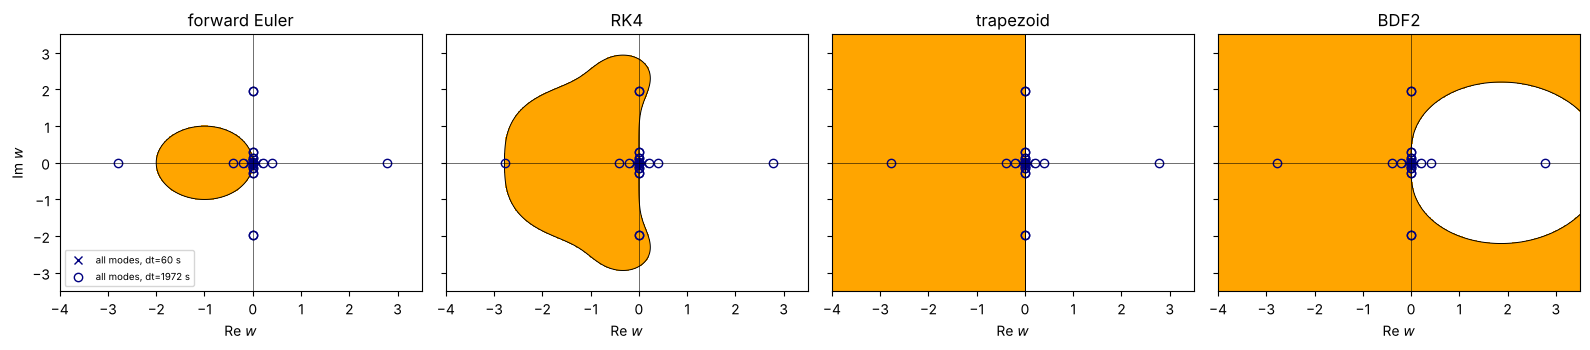

In [6]:
dt_rk4 = linearize.stable_dt(methods.amp_rk4, lam)

fig = plots.stability_regions(ev[mode_idx], dts=[60.0, dt_rk4], label="all modes,")
plt.show()

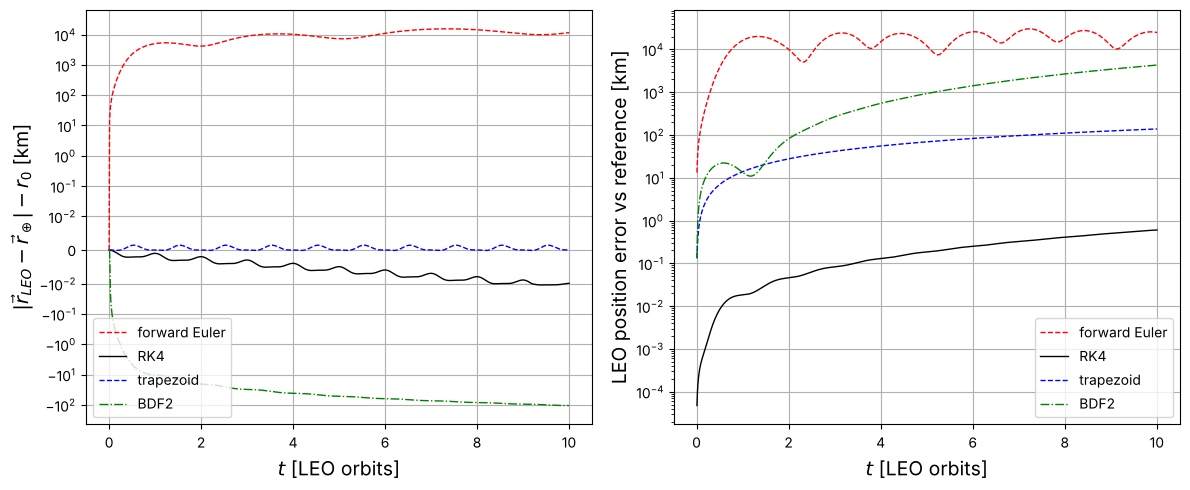

dt = 60 s, 105 steps per LEO orbit, 10.0 orbits
forward Euler  final radius change  +11652.1989 km   final position error   24740.8479 km
RK4            final radius change      -0.0099 km   final position error       0.6026 km
trapezoid      final radius change      +0.0000 km   final position error     138.2578 km
BDF2           final radius change    -105.5891 km   final position error    4301.0208 km


In [7]:
i_earth, i_leo = names.index("Earth"), names.index("LEO Orbiter")
dt = 60.0                                          # about 105 steps per LEO orbit
dt_ref = 5.0
t_end = dt * round(10 * P_fast / dt)               # 10 LEO orbits, whole number of steps
jac = lambda v: jacobian(v, mu)


def leo_offset(u):
	'''LEO position relative to Earth, for every row of u (km)'''
	return u[:, 6 * i_leo:6 * i_leo + 3] - u[:, 6 * i_earth:6 * i_earth + 3]


REF, time_ref = methods.rk4(f, x0, t_end, dt_ref)
runs = {}
for name, m in methods.METHODS.items():
	if name in ("trapezoid", "BDF2"):
		runs[name] = m["march"](f, x0, t_end, dt, jac)
	else:
		runs[name] = m["march"](f, x0, t_end, dt)

r0 = np.linalg.norm(leo_offset(x0[None, :])[0])
ref_at_dt = leo_offset(REF[::int(round(dt / dt_ref))])   # reference rows at the coarse times
styles = {"forward Euler": ("red", "--"), "RK4": ("black", "-"), "trapezoid": ("blue", "--"), "BDF2": ("green", "-.")}

fig = plt.figure(figsize=(12, 5))
ax1 = fig.add_subplot(121)
ax2 = fig.add_subplot(122)
for name, (U, tt) in runs.items():
	c, ls = styles[name]
	ax1.plot(tt / P_fast, np.linalg.norm(leo_offset(U), axis=1) - r0, color=c, linestyle=ls, linewidth=1, label=name)
	ax2.plot(tt[1:] / P_fast, np.linalg.norm(leo_offset(U) - ref_at_dt, axis=1)[1:], color=c, linestyle=ls, linewidth=1, label=name)

ax1.grid(True)
ax1.set_xlabel(r'$t$ [LEO orbits]', fontsize=14)
ax1.set_ylabel(r'$|\vec r_{LEO} - \vec r_\oplus| - r_0$ [km]', fontsize=14)
ax1.set_yscale('symlog', linthresh=1e-2)
ax1.legend()

ax2.grid(True)
ax2.set_xlabel(r'$t$ [LEO orbits]', fontsize=14)
ax2.set_ylabel(r'LEO position error vs reference [km]', fontsize=14)
ax2.set_yscale('log')
ax2.legend()

plt.tight_layout()
plt.show()

print(f"dt = {dt:.0f} s, {P_fast / dt:.0f} steps per LEO orbit, {t_end / P_fast:.1f} orbits")
for name, (U, tt) in runs.items():
	d = np.linalg.norm(leo_offset(U), axis=1) - r0
	e = np.linalg.norm(leo_offset(U) - ref_at_dt, axis=1)
	print(f"{name:14s} final radius change {d[-1]:+12.4f} km   final position error {e[-1]:12.4f} km")